In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import log_loss, brier_score_loss

from category_encoders import CatBoostEncoder


In [3]:
DATA_PATH = "data_processed/ball_by_ball_canonical.csv"

df = pd.read_csv(DATA_PATH, parse_dates=["date"])


joining winner from other csv winner

In [4]:
import pandas as pd

BALL_PATH = "data_processed/ball_by_ball_canonical.csv"
MATCH_PATH = "data_processed/match_master_clean_mergedwithclimate_teamnormalized.csv"

df_ball = pd.read_csv(BALL_PATH, parse_dates=["date"])
df_match = pd.read_csv(MATCH_PATH, parse_dates=["date"])


In [5]:
df_match_winner = df_match[["match_id", "winner"]].copy()

df_ball = df_ball.merge(
    df_match_winner,
    on="match_id",
    how="left"
)


In [6]:
df_model = df_ball[
    (df_ball["is_second_innings"] == 1) &
    (df_ball["has_elo"] == True) &
    (df_ball["winner"].notna())
].copy()


In [7]:
df_model["target"] = (
    df_model["batting_team"] == df_model["winner"]
).astype(int)


distribution check 

In [8]:
df_model["target"].value_counts(normalize=True)


target
1    0.501456
0    0.498544
Name: proportion, dtype: float64

In [9]:
end_balls = (
    df_model
    .sort_values(["match_id", "over", "ball"])
    .groupby("match_id")
    .tail(1)
)

(end_balls["target"] == 1).mean()


np.float64(0.5244779185210544)

In [12]:
# df_model.groupby("balls_remaining")["target"].mean().head(10)
df_model.groupby("balls_remaining")["target"].mean().tail(10)


balls_remaining
111    0.526177
112    0.523943
113    0.524574
114    0.524445
115    0.525334
116    0.522577
117    0.523676
118    0.528033
119    0.524910
120    0.625641
Name: target, dtype: float64

features for win prob model

In [11]:
NUMERIC_FEATURES = [
    "runs_remaining",
    "balls_remaining",
    "wickets_lost",
    "current_run_rate",
    "required_run_rate",
    "req_per_ball",
    "rr_diff",
    "batting_elo",
    "bowling_elo",
    "elo_diff",
    "phase_powerplay",
    "phase_death"
]

CATEGORICAL_FEATURES = [
    "venue",
    "league"
]

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES


checking match distribution over time

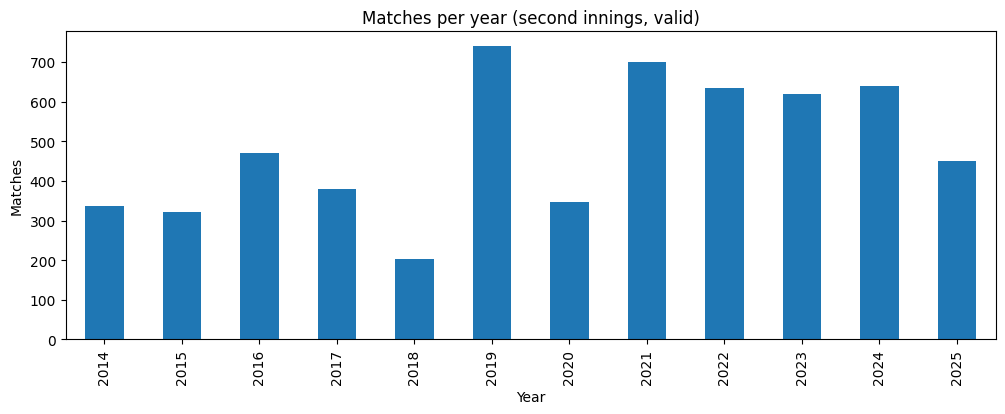

In [12]:
import matplotlib.pyplot as plt

match_counts = (
    df_model[["match_id", "date"]]
    .drop_duplicates()
    .assign(year=lambda x: x["date"].dt.year)
    .groupby("year")
    .size()
)

match_counts


match_counts.plot(kind="bar", figsize=(12,4))
plt.title("Matches per year (second innings, valid)")
plt.ylabel("Matches")
plt.xlabel("Year")
plt.show()


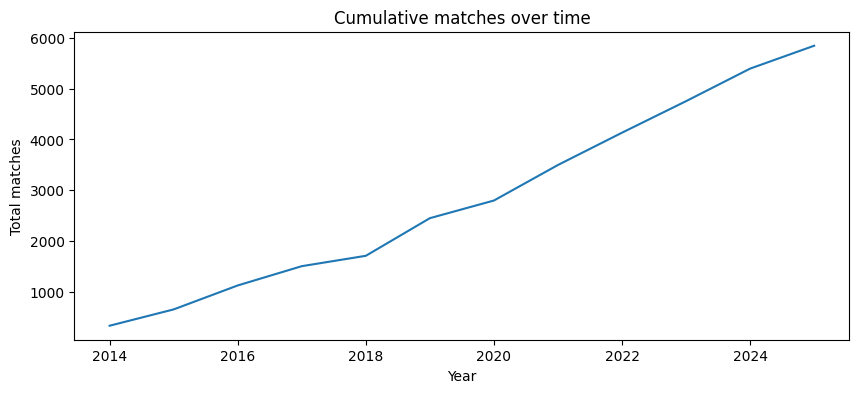

In [13]:
match_counts.cumsum().plot(figsize=(10,4))
plt.title("Cumulative matches over time")
plt.ylabel("Total matches")
plt.xlabel("Year")
plt.show()


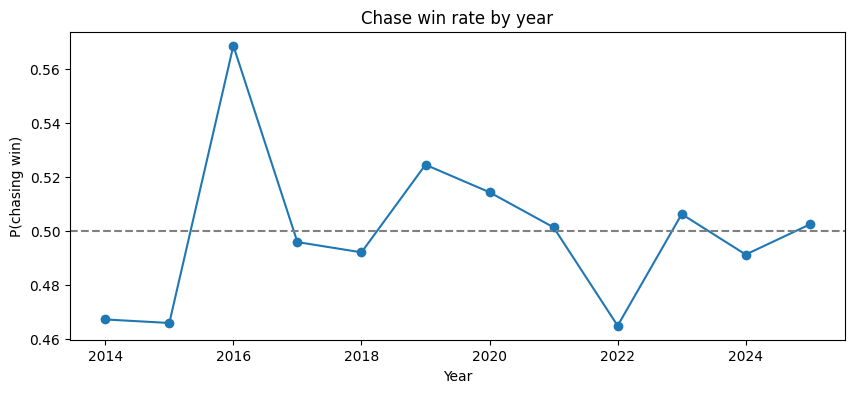

In [14]:
year_target = (
    df_model
    .assign(year=df_model["date"].dt.year)
    .groupby("year")["target"]
    .mean()
)

year_target.plot(marker="o", figsize=(10,4))
plt.axhline(0.5, linestyle="--", color="gray")
plt.title("Chase win rate by year")
plt.ylabel("P(chasing win)")
plt.xlabel("Year")
plt.show()


quantile based cutoffs

In [15]:
match_dates = (
    df_model[["match_id", "date"]]
    .drop_duplicates()
    .sort_values("date")
)

train_cutoff = match_dates["date"].quantile(0.65)
val_cutoff   = match_dates["date"].quantile(0.85)

train_cutoff, val_cutoff


(Timestamp('2022-06-10 00:00:00'), Timestamp('2024-03-27 20:24:00'))

In [16]:
train_df = df_model[df_model["date"] <= train_cutoff]
val_df   = df_model[
    (df_model["date"] > train_cutoff) &
    (df_model["date"] <= val_cutoff)
]
test_df  = df_model[df_model["date"] > val_cutoff]


In [17]:
def split_summary(df, name):
    print(f"{name}")
    print(" Matches:", df["match_id"].nunique())
    print(" Balls:", len(df))
    print(" Win rate:", round(df["target"].mean(), 3))
    print()

split_summary(train_df, "TRAIN")
split_summary(val_df, "VAL")
split_summary(test_df, "TEST")


TRAIN
 Matches: 3799
 Balls: 424728
 Win rate: 0.505

VAL
 Matches: 1166
 Balls: 129683
 Win rate: 0.489

TEST
 Matches: 877
 Balls: 97034
 Win rate: 0.502



In [18]:
from category_encoders import CatBoostEncoder

encoder = CatBoostEncoder(
    cols=CATEGORICAL_FEATURES,
    random_state=42
)

X_train = train_df[FEATURES]
y_train = train_df["target"]

X_val = val_df[FEATURES]
y_val = val_df["target"]

X_test = test_df[FEATURES]
y_test = test_df["target"]

X_train_enc = encoder.fit_transform(X_train, y_train)
X_val_enc   = encoder.transform(X_val)
X_test_enc  = encoder.transform(X_test)


logistic reg

In [19]:
from sklearn.linear_model import LogisticRegression

wp_model = LogisticRegression(
    max_iter=2000,
    solver="lbfgs",
    n_jobs=-1
)

wp_model.fit(X_train_enc, y_train)


ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

finding and filling n/a vals

In [20]:
X_train_enc.isna().sum().sort_values(ascending=False).head(15)


rr_diff              1473
runs_remaining       1216
required_run_rate    1216
req_per_ball         1216
current_run_rate      257
balls_remaining         0
wickets_lost            0
batting_elo             0
bowling_elo             0
elo_diff                0
phase_powerplay         0
phase_death             0
venue                   0
league                  0
dtype: int64

In [21]:
RATE_COLS = [
    "current_run_rate",
    "required_run_rate",
    "req_per_ball"
]

DIFF_COLS = [
    "rr_diff"
]

COUNT_COLS = [
    "runs_remaining"
]


In [22]:
nan_mask = X_train_enc.isna()

nan_counts = nan_mask.sum().sort_values(ascending=False)
nan_counts[nan_counts > 0]


rr_diff              1473
runs_remaining       1216
required_run_rate    1216
req_per_ball         1216
current_run_rate      257
dtype: int64

In [23]:
nan_rows = X_train_enc[nan_mask.any(axis=1)]
len(nan_rows)


1473

In [24]:
inspect_cols = [
    "match_id", "over", "ball",
    "runs_remaining", "balls_remaining",
    "current_run_rate", "required_run_rate",
    "req_per_ball", "rr_diff",
    "wickets_lost", 
]

df_nan_context = (
    train_df.loc[nan_rows.index, inspect_cols]
    .sort_values(["balls_remaining", "over", "ball"])
)

df_nan_context.head(20)


,match_id,over,ball,runs_remaining,balls_remaining,current_run_rate,required_run_rate,req_per_ball,rr_diff,wickets_lost
714,654055,19,6,NaN,0,6.80,NaN,NaN,NaN,7
1656,652265,19,6,NaN,0,7.30,NaN,NaN,NaN,7
2399,654063,19,6,NaN,0,7.35,NaN,NaN,NaN,7
4649,661695,19,6,NaN,0,5.40,NaN,NaN,NaN,8
5327,652269,19,6,NaN,0,8.60,NaN,NaN,NaN,8
6067,654079,19,6,NaN,0,9.90,NaN,NaN,NaN,6
6317,652273,19,6,NaN,0,6.40,NaN,NaN,NaN,8
6804,652277,19,6,NaN,0,7.40,NaN,NaN,NaN,3
7049,665701,19,6,NaN,0,8.90,NaN,NaN,NaN,7
7529,654083,19,6,NaN,0,7.45,NaN,NaN,NaN,5


In [25]:
df_nan_context.groupby("balls_remaining").size().head(10)


balls_remaining
0      1216
120     257
dtype: int64

this shows that end state is the one having nan vals so we can drop those cols

In [112]:
max_balls = df_model.groupby("match_id")["balls_remaining"].transform("max")

df_model = df_model[
    (df_model["balls_remaining"] > 0) &
    (df_model["balls_remaining"] < max_balls)
].copy()


train_df = df_model[df_model["date"] <= train_cutoff]
val_df   = df_model[
    (df_model["date"] > train_cutoff) &
    (df_model["date"] <= val_cutoff)
]
test_df  = df_model[df_model["date"] > val_cutoff]

X_train = train_df[FEATURES]
y_train = train_df["target"]

X_val = val_df[FEATURES]
y_val = val_df["target"]

X_test = test_df[FEATURES]
y_test = test_df["target"]

encoder = CatBoostEncoder(cols=CATEGORICAL_FEATURES, random_state=42)

X_train_enc = encoder.fit_transform(X_train, y_train)
X_val_enc   = encoder.transform(X_val)
X_test_enc  = encoder.transform(X_test)


In [113]:
nan_mask = X_train_enc.isna()

nan_counts = nan_mask.sum().sort_values(ascending=False)
nan_counts[nan_counts > 0]


Series([], dtype: int64)

In [114]:
RATE_COLS = [
    "current_run_rate",
    "required_run_rate",
    "req_per_ball"
]

# median from TRAIN
rate_medians = X_train_enc[RATE_COLS].median()

for col in RATE_COLS:
    X_train_enc[col] = X_train_enc[col].fillna(rate_medians[col])
    X_val_enc[col]   = X_val_enc[col].fillna(rate_medians[col])
    X_test_enc[col]  = X_test_enc[col].fillna(rate_medians[col])

# rr_diff = neutral
for col in ["rr_diff"]:
    X_train_enc[col] = X_train_enc[col].fillna(0.0)
    X_val_enc[col]   = X_val_enc[col].fillna(0.0)
    X_test_enc[col]  = X_test_enc[col].fillna(0.0)


In [115]:
assert X_train_enc.isna().sum().sum() == 0
assert X_val_enc.isna().sum().sum() == 0
assert X_test_enc.isna().sum().sum() == 0


In [116]:
nan_mask = X_train_enc.isna()

nan_counts = nan_mask.sum().sort_values(ascending=False)
nan_counts[nan_counts > 0]


Series([], dtype: int64)

In [117]:
from sklearn.linear_model import LogisticRegression

wp_model = LogisticRegression(
    max_iter=2000,
    solver="lbfgs",
    n_jobs=-1
)

wp_model.fit(X_train_enc, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [118]:
from sklearn.calibration import CalibratedClassifierCV

wp_model_cal = CalibratedClassifierCV(
    wp_model,
    method="isotonic",
    cv="prefit"
)

wp_model_cal.fit(X_val_enc, y_val)


C:\Users\kathe\AppData\Roaming\Python\Python314\site-packages\sklearn\calibration.py:330: FutureWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(


,estimator,"LogisticRegre...00, n_jobs=-1)"
,method,'isotonic'
,cv,'prefit'
,n_jobs,None
,ensemble,'auto'
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1


In [121]:
from sklearn.metrics import log_loss, brier_score_loss

val_probs  = wp_model_cal.predict_proba(X_val_enc)[:, 1]
test_probs = wp_model_cal.predict_proba(X_test_enc)[:, 1]

print("VAL LogLoss:", log_loss(y_val, val_probs))
print("VAL Brier:", brier_score_loss(y_val, val_probs))

print("TEST LogLoss:", log_loss(y_test, test_probs))
print("TEST Brier:", brier_score_loss(y_test, test_probs))


VAL LogLoss: 0.3625872387500237
VAL Brier: 0.11704516221751782
TEST LogLoss: 0.3966350587803018
TEST Brier: 0.12416307428000677


In [120]:
import joblib

joblib.dump(wp_model_cal, "models/wp_logistic_model.pkl")
joblib.dump(encoder, "models/wp_encoder.pkl")


['models/wp_encoder.pkl']

wpa formulation steps

In [122]:
# Encode features
df_model_enc = encoder.transform(df_model[FEATURES])

# Apply SAME imputations used in training
df_model_enc[RATE_COLS] = df_model_enc[RATE_COLS].fillna(rate_medians)
df_model_enc["rr_diff"] = df_model_enc["rr_diff"].fillna(0.0)

# Predict Win Probability
df_model["win_probability"] = wp_model_cal.predict_proba(df_model_enc)[:, 1]


In [123]:
df_model["win_probability"].describe()


count    643485.000000
mean          0.519713
std           0.359645
min           0.000000
25%           0.147922
50%           0.536056
75%           0.899667
max           1.000000
Name: win_probability, dtype: float64

In [124]:
df_model.groupby("balls_remaining")["win_probability"].mean().tail(10)


balls_remaining
110    0.533151
111    0.532505
112    0.529198
113    0.527513
114    0.527773
115    0.526770
116    0.524731
117    0.524482
118    0.526040
119    0.629660
Name: win_probability, dtype: float64

In [38]:
df_model[df_model["balls_remaining"] > 60]["win_probability"].describe()


count    353967.000000
mean          0.544224
std           0.328223
min           0.000000
25%           0.267516
50%           0.569165
75%           0.847864
max           1.000000
Name: win_probability, dtype: float64

In [44]:
df_model = df_model.sort_values(
    ["match_id", "innings", "over", "ball"]
).reset_index(drop=True)


In [45]:
df_model["wp_before"] = (
    df_model
    .groupby("match_id")["win_probability"]
    .shift(1)
)


In [46]:
df_model["wpa"] = (
    df_model["win_probability"] - df_model["wp_before"]
).fillna(0.0)


In [47]:
df_model["wpa"].describe()


count    649639.000000
mean          0.000046
std           0.031655
min          -0.803077
25%           0.000000
50%           0.000000
75%           0.000000
max           0.955501
Name: wpa, dtype: float64

In [49]:
df_model.sort_values("wpa", ascending=False).head(10)
# df_model.sort_values("wpa").head(10)


,match_id,innings,over,ball,batting_team,bowling_team,batter,bowler,fielder,runs_off_bat,...,bowling_team_matches,elo_diff,bat_first_team,bat_first_flag,has_elo,winner,target,win_probability,wp_before,wpa
642904,1475260,2,19,5,Quetta Gladiators,Islamabad United,Hassan Nawaz,Muhammad Shahzad,NaN,6,...,104.0,5.016649,Islamabad United,0,True,Quetta Gladiators,1,1.000000,0.044499,0.955501
476248,1347582,2,19,5,Worcestershire,Yorkshire,AW Finch,MD Fisher,NaN,6,...,110.0,-5.052037,Yorkshire,0,True,Worcestershire,1,0.993758,0.044199,0.949559
441625,1323153,2,19,5,St Kitts And Nevis Patriots,Guyana Amazon Warriors,D Pretorius,R Shepherd,NaN,6,...,76.0,-3.815565,Guyana Amazon Warriors,0,True,St Kitts And Nevis Patriots,1,0.956678,0.012987,0.943691
82394,931398,2,19,5,Zimbabwe,Bangladesh,N Madziva,Nasir Hossain,NaN,6,...,11.0,3.444422,Bangladesh,0,True,Zimbabwe,1,0.978577,0.044499,0.934077
512669,1369578,2,19,5,St Kitts And Nevis Patriots,St Lucia Kings,ADS Fletcher,RL Chase,NaN,6,...,27.0,-67.257570,St Lucia Kings,0,True,St Kitts And Nevis Patriots,1,0.965308,0.037457,0.927852
46967,804561,2,19,5,Worcestershire,Lancashire,OB Cox,JP Faulkner,NaN,6,...,21.0,-8.568174,Lancashire,0,True,Worcestershire,1,0.942919,0.015407,0.927512
206501,1157179,2,19,5,Bihar,Meghalaya,Vivek Kumar,A Singhania,NaN,6,...,5.0,-1.488935,Meghalaya,0,True,Bihar,1,1.000000,0.077236,0.922764
215079,1167141,2,19,5,Kent,Hampshire,AJ Blake,CP Wood,NaN,6,...,71.0,48.569706,Hampshire,0,True,Kent,1,0.978577,0.072056,0.906520
360057,1254116,2,19,5,Kolkata Knight Riders,Delhi Capitals,RA Tripathi,R Ashwin,NaN,6,...,101.0,6.735065,Delhi Capitals,0,True,Kolkata Knight Riders,1,0.978577,0.077236,0.901341
550917,1410457,2,19,5,Gloucestershire,Somerset,BG Charlesworth,BGF Green,NaN,6,...,144.0,-45.533298,Somerset,0,True,Gloucestershire,1,1.000000,0.110011,0.889989


batter aggregation

In [57]:
batter_wpa = (
    df_model
    .groupby("batter", as_index=False)
    .agg(
        balls_faced=("wpa", "count"),
        batting_wpa=("wpa", "sum"),
        batting_wpa_abs=("wpa", lambda x: x.abs().sum())
    )
)

# Efficiency metric
batter_wpa["batting_wpa_per_100"] = (
    batter_wpa["batting_wpa"] / batter_wpa["balls_faced"] * 100
)

batter_wpa = batter_wpa.sort_values("batting_wpa", ascending=False)


In [58]:
batter_wpa.head(20)
# batter_wpa.tail(20)


,batter,balls_faced,batting_wpa,batting_wpa_abs,batting_wpa_per_100
66,AD Hales,4589,10.269088,64.144270,0.223776
574,CH Gayle,2883,8.852036,44.000932,0.307043
1261,JM Vince,4205,7.930635,48.898821,0.188600
93,AJ Finch,3101,7.155149,40.203675,0.230737
793,E Lewis,1918,7.132972,28.231548,0.371896
2980,V Kohli,3074,6.679559,32.690389,0.217292
906,GJ Maxwell,2974,6.606823,39.076470,0.222153
546,CA Lynn,2508,6.422913,36.381839,0.256097
1928,N Pooran,3024,6.165763,40.621971,0.203894
684,DA Warner,3078,5.000257,34.543639,0.162452


bowling wpa

In [53]:
bowler_wpa = (
    df_model
    .groupby("bowler", as_index=False)
    .agg(
        balls_bowled=("wpa", "count"),
        bowling_wpa_raw=("wpa", "sum"),
        bowling_wpa_abs=("wpa", lambda x: x.abs().sum())
    )
)

# Flip sign: good bowling = positive value
bowler_wpa["bowling_wpa"] = -bowler_wpa["bowling_wpa_raw"]

bowler_wpa["bowling_wpa_per_100"] = (
    bowler_wpa["bowling_wpa"] / bowler_wpa["balls_bowled"] * 100
)

bowler_wpa = bowler_wpa.sort_values("bowling_wpa", ascending=False)


In [54]:
bowler_wpa.head(20)
# bowler_wpa.tail(20)


,bowler,balls_bowled,bowling_wpa_raw,bowling_wpa_abs,bowling_wpa,bowling_wpa_per_100
1933,SP Narine,4499,-10.857526,46.761732,10.857526,0.241332
1787,Rashid Khan,3759,-7.215440,45.992010,7.215440,0.191951
815,Imran Tahir,3330,-5.835981,36.556128,5.835981,0.175255
2323,Wahab Riaz,2293,-3.623050,37.653913,3.623050,0.158005
1431,Mustafizur Rahman,2315,-3.612307,29.179932,3.612307,0.156039
1585,PM Siddle,1317,-3.580025,19.942802,3.580025,0.271832
735,HF Gurney,1130,-3.555143,19.397653,3.555143,0.314614
916,JJ Bumrah,2220,-3.323250,29.667395,3.323250,0.149696
1601,PWH de Silva,2065,-3.311574,24.867296,3.311574,0.160367
1021,K Rabada,2081,-3.170601,33.672075,3.170601,0.152359


combining

In [59]:
player_wpa = (
    batter_wpa
    .merge(
        bowler_wpa,
        left_on="batter",
        right_on="bowler",
        how="outer"
    )
)

# Resolve name
player_wpa["player"] = (
    player_wpa["batter"]
    .combine_first(player_wpa["bowler"])
)

# Clean up
player_wpa = (
    player_wpa
    .drop(columns=["batter", "bowler", "bowling_wpa_raw"])
    .fillna(0)
)

# Net contribution
player_wpa["net_wpa"] = (
    player_wpa["batting_wpa"] + player_wpa["bowling_wpa"]
)

player_wpa["total_balls"] = (
    player_wpa["balls_faced"] + player_wpa["balls_bowled"]
)

player_wpa = player_wpa.sort_values("net_wpa", ascending=False)


filtering

In [60]:
MIN_BATTING_BALLS = 200
MIN_BOWLING_BALLS = 200

player_wpa_filtered = player_wpa[
    (player_wpa["balls_faced"] >= MIN_BATTING_BALLS) |
    (player_wpa["balls_bowled"] >= MIN_BOWLING_BALLS)
].copy()


In [63]:
player_wpa = player_wpa.sort_values("batting_wpa_per_100", ascending=False)

player_wpa_filtered.head(25)


,balls_faced,batting_wpa,batting_wpa_abs,batting_wpa_per_100,balls_bowled,bowling_wpa_abs,bowling_wpa,bowling_wpa_per_100,player,net_wpa,total_balls
76,4589.0,10.269088,64.144270,0.223776,0.0,0.000000,0.000000,0.000000,AD Hales,10.269088,4589.0
2915,1411.0,-1.353867,25.833971,-0.095951,4499.0,46.761732,10.857526,0.241332,SP Narine,9.503659,5910.0
661,2883.0,8.852036,44.000932,0.307043,165.0,0.764474,-0.038335,-0.023234,CH Gayle,8.813701,3048.0
1424,4205.0,7.930635,48.898821,0.188600,24.0,0.071814,-0.036920,-0.153833,JM Vince,7.893715,4229.0
104,3101.0,7.155149,40.203675,0.230737,39.0,1.000297,0.699261,1.792978,AJ Finch,7.854411,3140.0
905,1918.0,7.132972,28.231548,0.371896,0.0,0.000000,0.000000,0.000000,E Lewis,7.132972,1918.0
3394,3074.0,6.679559,32.690389,0.217292,18.0,0.390374,0.071442,0.396900,V Kohli,6.751001,3092.0
632,2508.0,6.422913,36.381839,0.256097,0.0,0.000000,0.000000,0.000000,CA Lynn,6.422913,2508.0
2185,3024.0,6.165763,40.621971,0.203894,0.0,0.000000,0.000000,0.000000,N Pooran,6.165763,3024.0
1034,2974.0,6.606823,39.076470,0.222153,1446.0,16.454316,-0.930091,-0.064322,GJ Maxwell,5.676732,4420.0


In [64]:
player_wpa_filtered.to_csv(
    "data_processed/player_wpa_summary.csv",
    index=False
)


analyse player

In [65]:
def analyze_player(player_name, df_model, player_wpa):
    # Ball-level data
    balls = df_model[
        (df_model["batter"] == player_name) |
        (df_model["bowler"] == player_name)
    ].copy()

    if balls.empty:
        print(f"No data found for {player_name}")
        return

    # Batting vs Bowling split
    batting = balls[balls["batter"] == player_name]
    bowling = balls[balls["bowler"] == player_name]

    summary = {
        "Player": player_name,
        "Batting balls": len(batting),
        "Bowling balls": len(bowling),
        "Batting WPA": batting["wpa"].sum(),
        "Bowling WPA": -bowling["wpa"].sum(),
        "Net WPA": batting["wpa"].sum() - bowling["wpa"].sum(),
        "Clutch WPA (last 24 balls)": balls[balls["balls_remaining"] <= 24]["wpa"].sum(),
        "High-leverage WPA (0.2–0.8 WP)": balls[
            (balls["win_probability"].between(0.2, 0.8))
        ]["wpa"].sum()
    }

    return pd.Series(summary)


In [66]:
analyze_player("MS Dhoni", df_model, player_wpa_filtered)


Player                            MS Dhoni
Batting balls                         1257
Bowling balls                            0
Batting WPA                      -1.172681
Bowling WPA                           -0.0
Net WPA                          -1.172681
Clutch WPA (last 24 balls)        0.231669
High-leverage WPA (0.2–0.8 WP)    0.597465
dtype: object

compare players

In [67]:
def compare_players(players, player_wpa):
    cols = [
        "player",
        "batting_wpa",
        "bowling_wpa",
        "net_wpa",
        "balls_faced",
        "balls_bowled"
    ]

    return (
        player_wpa[player_wpa["player"].isin(players)]
        [cols]
        .sort_values("net_wpa", ascending=False)
        .reset_index(drop=True)
    )


In [70]:
compare_players(
    ["V Kohli", "RG Sharma", "SA Yadav"],
    player_wpa_filtered
)


,player,batting_wpa,bowling_wpa,net_wpa,balls_faced,balls_bowled
0,V Kohli,6.679559,0.071442,6.751001,3074.0,18.0
1,SA Yadav,3.707021,0.000000,3.707021,2106.0,0.0
2,RG Sharma,1.880298,-0.103858,1.776440,2432.0,25.0


mvp's

In [71]:
def clutch_analysis(player_name, df_model, balls_cutoff=24):
    balls = df_model[
        ((df_model["batter"] == player_name) |
         (df_model["bowler"] == player_name)) &
        (df_model["balls_remaining"] <= balls_cutoff)
    ]

    if balls.empty:
        return None

    return {
        "Player": player_name,
        "Clutch balls": len(balls),
        "Clutch WPA": balls["wpa"].sum(),
        "Avg WPA per clutch ball": balls["wpa"].mean(),
        "Big moments (|WPA| > 0.05)": (balls["wpa"].abs() > 0.05).sum()
    }


In [75]:
clutch_analysis("V Kohli", df_model)


{'Player': 'V Kohli',
 'Clutch balls': 247,
 'Clutch WPA': np.float64(1.9820048456237074),
 'Avg WPA per clutch ball': np.float64(0.008024311115885455),
 'Big moments (|WPA| > 0.05)': np.int64(32)}

clutch player leaderboard

In [76]:
def top_clutch_players(df_model, min_clutch_balls=50):
    clutch = df_model[df_model["balls_remaining"] <= 24]

    leaderboard = (
        clutch
        .groupby("batter", as_index=False)
        .agg(
            clutch_balls=("wpa", "count"),
            clutch_wpa=("wpa", "sum")
        )
    )

    leaderboard = leaderboard[
        leaderboard["clutch_balls"] >= min_clutch_balls
    ]

    return leaderboard.sort_values("clutch_wpa", ascending=False)


In [77]:
top_clutch_players(df_model).head(20)


,batter,clutch_balls,clutch_wpa
2065,SO Hetmyer,333,2.530127
550,DA Miller,646,2.370430
1502,Mohammad Nabi,217,2.096992
74,AJ Finch,162,2.026461
2153,Shahid Afridi,168,1.984724
56,AD Russell,711,1.977162
2393,V Kohli,243,1.924924
1038,JP Duminy,126,1.855509
2257,T Stubbs,145,1.801102
726,GG White,80,1.730139


In [78]:
def wpa_distribution(player_name, df_model):
    balls = df_model[df_model["batter"] == player_name]

    return balls["wpa"].describe(percentiles=[0.01, 0.05, 0.95, 0.99])


In [79]:
wpa_distribution('V Kohli', df_model)

count    3074.000000
mean        0.002173
std         0.028966
min        -0.139466
1%         -0.087222
5%         -0.026460
50%         0.000000
95%         0.046065
99%         0.077879
max         0.864288
Name: wpa, dtype: float64

In [80]:
def match_impact(player_name, df_model):
    balls = df_model[
        (df_model["batter"] == player_name) |
        (df_model["bowler"] == player_name)
    ]

    impact = (
        balls
        .groupby("match_id")["wpa"]
        .sum()
        .reset_index(name="match_wpa")
    )

    return impact.sort_values("match_wpa", ascending=False)


In [83]:
match_impact("JJ Bumrah", df_model).head(10)


,match_id,match_wpa
88,1304097,0.325684
65,1216541,0.306968
60,1216492,0.304845
22,980917,0.287891
83,1304060,0.240816
70,1254070,0.224027
81,1304048,0.215412
6,734045,0.207374
10,895819,0.192379
16,951371,0.151962


In [84]:
def player_dashboard(player):
    return pd.concat([
        analyze_player(player, df_model, player_wpa_filtered),
        pd.Series(clutch_analysis(player, df_model))
    ], axis=0)


In [85]:
player_dashboard("V Kohli")

Player                             V Kohli
Batting balls                         3074
Bowling balls                           18
Batting WPA                       6.679559
Bowling WPA                       0.071442
Net WPA                           6.751001
Clutch WPA (last 24 balls)        1.982005
High-leverage WPA (0.2–0.8 WP)    2.528285
Player                             V Kohli
Clutch balls                           247
Clutch WPA                        1.982005
Avg WPA per clutch ball           0.008024
Big moments (|WPA| > 0.05)              32
dtype: object

final wpa calculation on whole dataset

In [95]:
# Load or reference your full ball-by-ball dataset
# (use the correct variable name you already have in memory)

df_all = df_ball.copy()

df_all = df_all[
    (df_all["is_second_innings"] == 1) &
    (df_all["has_elo"] == True)
].copy()

df_all = df_all.sort_values(
    ["match_id", "innings", "over", "ball"]
).reset_index(drop=True)


In [86]:
# TRAIN + VAL combined
X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)


In [88]:
X_trainval_enc = encoder.transform(X_trainval)


In [89]:
X_trainval_enc[RATE_COLS] = X_trainval_enc[RATE_COLS].fillna(rate_medians)
X_trainval_enc["rr_diff"] = X_trainval_enc["rr_diff"].fillna(0.0)


In [90]:
from sklearn.base import clone

final_wp_model = clone(wp_model)

final_wp_model.fit(X_trainval_enc, y_trainval)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [92]:
from sklearn.isotonic import IsotonicRegression

final_calibrator = IsotonicRegression(out_of_bounds="clip")

final_calibrator.fit(
    final_wp_model.predict_proba(X_val_enc)[:, 1],
    y_val
)


,y_min,None
,y_max,None
,increasing,True
,out_of_bounds,'clip'


In [100]:
X_all_enc = encoder.transform(df_all[FEATURES])

X_all_enc[RATE_COLS] = X_all_enc[RATE_COLS].fillna(rate_medians)
X_all_enc["rr_diff"] = X_all_enc["rr_diff"].fillna(0.0)


In [101]:
raw_probs = final_wp_model.predict_proba(X_all_enc)[:, 1]
df_all["win_probability"] = final_calibrator.predict(raw_probs)


ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [105]:
nan_counts = X_all_enc.isna().sum()
nan_counts[nan_counts > 0]


runs_remaining    1806
dtype: int64

In [106]:
# Fill runs_remaining NaNs
X_all_enc["runs_remaining"] = X_all_enc["runs_remaining"].fillna(0.0)


In [107]:
assert X_all_enc.isna().sum().sum() == 0, "NaNs still present in X_all_enc"


In [109]:
raw_probs = final_wp_model.predict_proba(X_all_enc)[:, 1]
df_all["win_probability"] = final_calibrator.predict(raw_probs)


In [111]:
df_all.groupby("balls_remaining")["win_probability"].mean().tail(10)


balls_remaining
111    0.531951
112    0.528391
113    0.526535
114    0.526257
115    0.525090
116    0.522888
117    0.522182
118    0.523306
119    0.519510
120    0.602804
Name: win_probability, dtype: float64